Mantis zero-shot features on LIAS (issue #7)

In [1]:
import sys
from pathlib import Path

# add the repo root so LIAS/ can be imported
sys.path.insert(0, str(Path.cwd().parent))

import torch
# use the GPU if there is one, otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cpu


In [2]:
import torch
import torch.nn.functional as F

# stretch or shrink each series to 512 samples
def resize(X):
    X_scaled = F.interpolate(torch.tensor(X, dtype=torch.float), size=512, mode='linear', align_corners=False)
    return X_scaled.numpy()

In [3]:
from mantis.architecture import MantisV1

# build the model on the device picked above (GPU or CPU)
network = MantisV1(device=device)
# load the pretrained weights, brings the model to the laptop
network = network.from_pretrained("paris-noah/Mantis-8M")
# Maybe the next task is to look into this a bit more

c:\Users\thavi\Documents\Personal\school\projects\tele6500\mcsa_tsfm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```
isa (512 samples) -> Mantis -> 256 numbers
isb (512 samples) -> Mantis -> 256 numbers
isc (512 samples) -> Mantis -> 256 numbers
                   joined:     768 numbers
```


In [4]:
import numpy as np

# fake data: 2 samples, 1 channel, 1024 long (Mantis resizes it to 512 inside)
X = np.random.randn(2, 1, 1024).astype(np.float32) 


In [5]:
X[0].shape

(1, 1024)

In [6]:
from mantis.trainer import MantisTrainer

# wrap the model so we can call transform
model = MantisTrainer(device=device, network=network)
# get the features
Z = model.transform(X) # X is the time series dataset

In [7]:
Z.shape

(2, 256)

In [8]:
# input shape vs feature shape
print(X.shape, Z.shape)

(2, 1, 1024) (2, 256)


LIAS data, first 2 windows

In [9]:
from LIAS.prepare_LIAS import process_single_file

# same window settings as the MOMENT notebook
WINDOW_SIZE = 1024
OVERLAP = int(WINDOW_SIZE/2)

# cut one file into windows, one list per phase
windows_a, windows_b, windows_c = process_single_file("ccs0.csv", WINDOW_SIZE, OVERLAP)

# check what we got
print("Windows in this file:", len(windows_a))
print("One window's metadata:", windows_a[0]["metadata"])
print("One window's length:", len(windows_a[0]["data"]))

Windows in this file: 25
One window's metadata: {'file_name': 'ccs0.csv', 'window_num': 0, 'window_size': 1024, 'overlap': 512, 'signal_type': 'isa'}
One window's length: 512


In [10]:
# only the first 2 windows
N_WINDOWS = 2

# isa, isb, isc as 3 channels -> shape (2, 3, 512)
X_lias = np.stack([
    np.stack([windows_a[i]["data"], windows_b[i]["data"], windows_c[i]["data"]])
    # instead of stacking the data directly, we could also apply some preprocessing here if needed, do that on your own time
    for i in range(N_WINDOWS)
]).astype(np.float32)

print("X_lias shape:", X_lias.shape)

X_lias shape: (2, 3, 512)


In [11]:
# one window, one phase: Mantis wants (samples, channels, length)
x_one = np.array(windows_a[0]["data"], dtype=np.float32).reshape(1, 1, -1)

Z_one = model.transform(x_one)

print("Z_one shape:", Z_one.shape)

Z_one shape: (1, 256)


In [12]:
# features for the real windows
Z_lias = model.transform(X_lias)

print("Z_lias shape:", Z_lias.shape)

Z_lias shape: (2, 768)


In [13]:
# one file per class, all at low load
import pandas as pd

FILES = {"ccs0.csv": "healthy", "ccs60.csv":"one broken bar", "ccs120.csv":"two broken bars"}

X_list, meta_list = [], []
for f, label in FILES.items():
    wa, wb, wc = process_single_file(f, WINDOW_SIZE, OVERLAP)
    for i in range(len(wa)):
        # same as above: the 3 phases become 3 channels
        X_list.append(np.stack([wa[i]["data"], wb[i]["data"], wc[i]["data"]]))
        meta_list.append({"file_name":f, "window_num":i, "label":label})

X_more = np.stack(X_list).astype(np.float32)
meta_more = pd.DataFrame(meta_list)
print(X_more.shape)
print(meta_more["label"].value_counts())

(75, 3, 512)
label
healthy            25
one broken bar     25
two broken bars    25
Name: count, dtype: int64


In [14]:
from mantis.architecture import MantisV2

# name: (model class, Hugging Face ID, extra loading options)
CHECKPOINTS = {
    "Mantis-8M":  (MantisV1, "paris-noah/Mantis-8M", {}),
    "MantisPlus": (MantisV1, "paris-noah/MantisPlus", {}),
    "UTICA":      (MantisV1, "fegounna/Utica", {"revision": "3cff4f954191b5bf9839b7a41117e2b24e7693ab"}),
    "MantisV2":   (MantisV2, "paris-noah/MantisV2", {}),
}

features = {}
for name, (cls, hf_id, kwargs) in CHECKPOINTS.items():
    # build the model and load that checkpoint's weights
    net = cls(device=device).from_pretrained(hf_id, **kwargs)
    # same transform as before, now all 75 windows
    features[name] = MantisTrainer(device=device, network=net).transform(X_more)

    print(name, features[name].shape)

Mantis-8M (75, 768)
MantisPlus (75, 768)
UTICA (75, 768)
MantisV2 (75, 768)


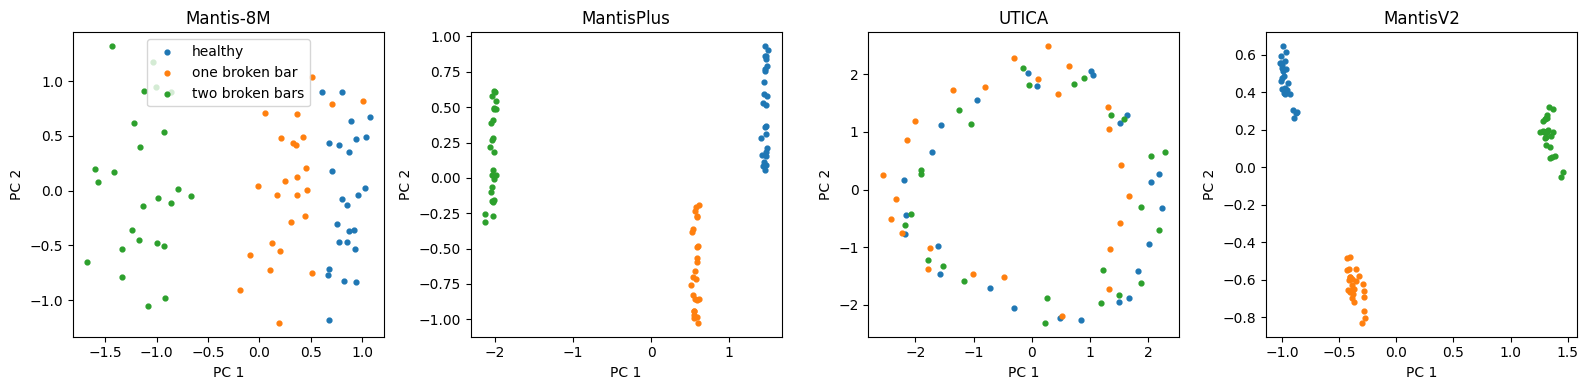

In [15]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# one plot per checkpoint, side by side
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (name, Z) in zip(axes, features.items()):
    # 768 features -> 2 numbers per window
    Z2 = PCA(n_components=2).fit_transform(Z)
    # one color per class
    for label in FILES.values():
        m = (meta_more["label"] == label).values
        ax.scatter(Z2[m, 0], Z2[m, 1], s=12, label=label)
    ax.set_title(name)
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")

axes[0].legend()
plt.tight_layout()
plt.show()


## What the plots show

Four Mantis checkpoints (Mantis-8M, MantisPlus, UTICA, MantisV2) were run zero-shot on 75 LIAS windows: all 25 windows from one healthy file (ccs0), one 1-broken-bar file (ccs60) and one 2-broken-bar file (ccs120), all at low speed. The three phases (isa, isb, isc) are the three channels, and each window gives 768 features (256 per phase). PCA reduces the features to 2 dimensions for plotting; the labels are only used to color the points.

**Result:** [which checkpoints] separate the three classes [cleanly / partly / not at all].

**Caveat:** there is one recording per class, so the separation could come from the recording rather than the fault.

**Next steps:**
- many files per class, with the train-test split done by file
- a simple classifier on the features (logistic regression or SVM) to get an accuracy for each checkpoint
- resolve the pandas<3 conflict so `mantis-tsfm` can go into `pyproject.toml`


In [16]:
import pandas as pd

# file name and window number for each row
metadata = pd.DataFrame([windows_a[i]["metadata"] for i in range(N_WINDOWS)])[["file_name", "window_num"]]
# put them next to the features
df_features = pd.concat([metadata, pd.DataFrame(Z_lias)], axis=1)
df_features

,file_name,window_num,0,1,2,3,4,5,6,7,...,758,759,760,761,762,763,764,765,766,767
0,ccs0.csv,0,-0.741933,0.672953,1.810726,6.033775,0.960223,-4.464929,-1.976164,-0.116092,...,4.285138,-3.918342,-3.577071,3.712860,2.026669,-1.226161,-3.826372,-2.362254,2.129551,-2.020921
1,ccs0.csv,1,-0.733858,0.644204,1.817023,6.052924,0.955437,-4.488215,-1.947238,-0.093701,...,4.300158,-3.921416,-3.604781,3.714683,2.040221,-1.182129,-3.819760,-2.378721,2.155533,-2.027821


In [17]:
# load UTICA on its own (it is also in the comparison above)
network = MantisV1(device=device)
network = network.from_pretrained("fegounna/Utica", revision="3cff4f954191b5bf9839b7a41117e2b24e7693ab")

### Full LIAS: Mantis features and train-test split (issue #17)


In [18]:
from LIAS.prepare_LIAS import process_all_LIAS_files
from common.mantis_embeddings_LIAS import get_embeddings_in_batches, embeddings_to_dataframe

# cut every LIAS file into windows, one list per phase
windows_a, windows_b, windows_c = process_all_LIAS_files(WINDOW_SIZE, OVERLAP)

# back to Mantis-8M (the cells above left UTICA loaded)
network = MantisV1(device=device).from_pretrained("paris-noah/Mantis-8M")
model = MantisTrainer(device=device, network=network)

# 256 features per window, per phase
emb_a, meta_a = get_embeddings_in_batches(windows_a, model, batch_size=256)
emb_b, meta_b = get_embeddings_in_batches(windows_b, model, batch_size=256)
emb_c, meta_c = get_embeddings_in_batches(windows_c, model, batch_size=256)


Found 162 files: ['ccs0.csv', 'ccs1.csv', 'ccs10.csv', 'ccs100.csv', 'ccs101.csv', 'ccs102.csv', 'ccs103.csv', 'ccs104.csv', 'ccs105.csv', 'ccs106.csv', 'ccs107.csv', 'ccs108.csv', 'ccs109.csv', 'ccs11.csv', 'ccs110.csv', 'ccs111.csv', 'ccs112.csv', 'ccs113.csv', 'ccs114.csv', 'ccs115.csv', 'ccs116.csv', 'ccs117.csv', 'ccs12.csv', 'ccs120.csv', 'ccs121.csv', 'ccs122.csv', 'ccs123.csv', 'ccs124.csv', 'ccs125.csv', 'ccs126.csv', 'ccs127.csv', 'ccs128.csv', 'ccs129.csv', 'ccs13.csv', 'ccs130.csv', 'ccs131.csv', 'ccs132.csv', 'ccs133.csv', 'ccs134.csv', 'ccs135.csv', 'ccs136.csv', 'ccs137.csv', 'ccs14.csv', 'ccs140.csv', 'ccs141.csv', 'ccs142.csv', 'ccs143.csv', 'ccs144.csv', 'ccs145.csv', 'ccs146.csv', 'ccs147.csv', 'ccs148.csv', 'ccs149.csv', 'ccs15.csv', 'ccs150.csv', 'ccs151.csv', 'ccs152.csv', 'ccs153.csv', 'ccs154.csv', 'ccs155.csv', 'ccs156.csv', 'ccs157.csv', 'ccs16.csv', 'ccs160.csv', 'ccs161.csv', 'ccs162.csv', 'ccs163.csv', 'ccs164.csv', 'ccs165.csv', 'ccs166.csv', 'ccs167.csv',

Processing files: 100%|██████████| 162/162 [00:06<00:00, 26.61it/s]


In [24]:
emb_a

tensor([[-0.7419,  0.6730,  1.8107,  ..., -2.3844,  2.0655, -2.1008],
        [-0.7339,  0.6442,  1.8170,  ..., -2.3947,  2.0547, -2.1017],
        [-0.7436,  0.6271,  1.8684,  ..., -2.3716,  2.0681, -2.0931],
        ...,
        [-0.9706,  0.5273,  2.3403,  ..., -1.9519,  2.4924, -2.4033],
        [-0.9529,  0.5753,  2.2774,  ..., -1.9296,  2.4571, -2.3571],
        [-0.9197,  0.5691,  2.2871,  ..., -1.8649,  2.3567, -2.2335]])

In [25]:
emb_a.shape

torch.Size([4050, 256])

In [23]:
emb_b

tensor([[-0.8235,  0.6070,  1.7842,  ..., -2.4687,  1.9952, -1.9797],
        [-0.8573,  0.6048,  1.8195,  ..., -2.4324,  2.0127, -1.9644],
        [-0.8296,  0.6514,  1.7727,  ..., -2.4337,  1.9956, -1.9746],
        ...,
        [-1.3209,  0.4924,  2.3482,  ..., -2.1103,  2.6237, -2.3095],
        [-1.3209,  0.5078,  2.3719,  ..., -2.0495,  2.6518, -2.2718],
        [-1.3628,  0.4913,  2.4699,  ..., -2.0909,  2.6733, -2.2141]])

In [26]:
emb_b.shape

torch.Size([4050, 256])

In [ ]:
meta_a

[{'file_name': 'ccs0.csv',
  'window_num': 0,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 1,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 2,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 3,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 4,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 5,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 6,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 7,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 'isa'},
 {'file_name': 'ccs0.csv',
  'window_num': 8,
  'window_size': 1024,
  'overlap': 512,
  'signal_type': 

In [19]:
from common.feature_merging import rename_and_merge

# one row per window: file_name, window_num, mantis_a_0 ... mantis_c_255
df_mantis = rename_and_merge(embeddings_to_dataframe(emb_a, meta_a),
                             embeddings_to_dataframe(emb_b, meta_b),
                             embeddings_to_dataframe(emb_c, meta_c),
                             feature_type="mantis")
df_mantis.shape   # (4050, 770)


ModuleNotFoundError: No module named 'common.feature_merging'

In [ ]:
from common.classification import train_test_split_LIAS

# split by file, stratified on file_group: all windows of a file stay on one side
train_df, test_df = train_test_split_LIAS(df_mantis, test_size=0.2, seed=67)

# check: every condition-and-speed group is in both sets
pd.DataFrame({"train": train_df.groupby("file_group")["file_name"].nunique(),
              "test":  test_df.groupby("file_group")["file_name"].nunique()})


Seed 67: 105 training files (2625 windows), 27 test files (675 windows).


,train,test
file_group,,
healthy_high,14,4
healthy_low,14,4
healthy_med,14,4
one_broken_high,14,4
one_broken_low,7,1
one_broken_med,14,4
two_broken_high,14,4
two_broken_low,7,1
two_broken_med,7,1


### Scaling, model fitting and evaluation (issue #18)


In [ ]:
from sklearn.preprocessing import StandardScaler

# the Mantis feature columns: mantis_a_0 ... mantis_c_255
feature_cols = [col for col in train_df.columns if col.startswith("mantis_")]

X_train, y_train = train_df[feature_cols], train_df["class"]
X_test,  y_test  = test_df[feature_cols],  test_df["class"]

# learn mean and std on the training set only, apply to both (no test leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(X_train_scaled.shape, X_test_scaled.shape)   # (2625, 768) (675, 768)


(2625, 768) (675, 768)


In [ ]:
from common.classification import train_svc_model, evaluate_model

svc = train_svc_model(X_train_scaled, y_train)
evaluate_model(y_test, svc.predict(X_test_scaled), "Mantis-8M, SVM")


Training SVM model with rbf kernel and balanced class weights...
SVM model training complete with rbf kernel.

Classification Report (Mantis-8M, SVM):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       300
           2       1.00      1.00      1.00       225
           3       1.00      1.00      1.00       150

    accuracy                           1.00       675
   macro avg       1.00      1.00      1.00       675
weighted avg       1.00      1.00      1.00       675


Confusion Matrix (Mantis-8M, SVM):
[[300   0   0]
 [  0 225   0]
 [  0   0 150]]


In [ ]:
from common.classification import train_log_reg_model

log_reg = train_log_reg_model(X_train_scaled, y_train)
evaluate_model(y_test, log_reg.predict(X_test_scaled), "Mantis-8M, logistic regression")


Training Logistic Regression model with solver='lbfgs', penalty='l2', C=1.0 and balanced class weights...
Logistic Regression model training complete.

Classification Report (Mantis-8M, logistic regression):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       300
           2       1.00      1.00      1.00       225
           3       1.00      1.00      1.00       150

    accuracy                           1.00       675
   macro avg       1.00      1.00      1.00       675
weighted avg       1.00      1.00      1.00       675


Confusion Matrix (Mantis-8M, logistic regression):
[[300   0   0]
 [  0 225   0]
 [  0   0 150]]


c:\Users\thavi\Documents\Personal\school\projects\tele6500\mcsa_tsfm\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
